# City track — up-to-date forecasts for Kyiv, Lviv and Odesa

The main track (`model.ipynb`) stops on 4 Sep 2026: the official data feed died and the alert system changed.
This track keeps going **until today** for cities whose official Telegram channels post every alert and all-clear.
Everything else is the same — features, models, rolling backtest, metrics — with one data switch: the target comes from the channels.

| city | channel | unit | validated against (official data) |
|---|---|---|---|
| Kyiv | `@kyivcityofficial` (Kyiv City State Administration) | Kyiv City | Kyiv City |
| Lviv | `@dczloda` (Lviv oblast civil protection) | Lvivskyi raion | Lviv oblast-level + Lvivskyi raion alerts |
| Odesa | `@odesacityofficial` ("Одеса. Офіційно") | Odeskyi raion | Odesa oblast-level + Odeskyi raion alerts |

Kharkiv was intended too, but no official channel posting alerts was found (the oblast administration posts news only).

**Differences to the main track, by necessity:** regional features use only the three tracked cities (the state of other oblasts is
unknown after 7 Sep); hyperparameters are taken from the main track (no re-tuning); the **test period — the last 5 weeks up to
10 Oct 2026 — lies entirely in the new yellow/red system**, while training is almost entirely before it. Yellow and red both count as "alert".

In [1]:
import sys; sys.path.insert(0, "..")
%matplotlib inline
import pandas as pd
pd.set_option("display.width", 200)
from ua_alerts import backtest, city_track as ct, config, data, evaluation, telegram

panel, indicator, intervals = ct.load_inputs()
print(f"data until {ct.data_end():%Y-%m-%d %H:%M} UTC")
pd.DataFrame({c: [len(telegram.load(v['channel']))] for c, v in ct.CITIES.items()}, index=["messages scraped"])

data until 2026-10-10 22:00 UTC


,Kyiv,Lviv,Odesa
messages scraped,4559,372,7891


## 1. From messages to alert intervals

Each channel uses fixed templates, e.g. Kyiv "‼️УВАГА! У Києві оголошена повітряна тривога!" / "🟡 … дронова небезпека!" and
"❕Відбій повітряної тривоги!"; Odesa "🔴 Одеський район - повітряна тривога!" / "🟢 … відбій"; Lviv "Увага! Львівська область! Повітряна
тривога!" (per raion since September). A start opens an interval, the next all-clear closes it; repeated starts and stray all-clears
are ignored. A message is used only if it was published before the end of the data.

In [2]:
counts = intervals.groupby(["region", intervals.started_at.dt.tz_convert(config.LOCAL_TZ).dt.strftime("%Y-%m")]).size().unstack(0)
counts.fillna(0).astype(int).T

started_at,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
region,,,,,,,,,,,,,
Kyiv,19,41,24,57,41,39,35,58,46,59,121,190,81
Lviv,11,16,9,11,16,12,7,15,10,2,2,6,1
Odesa,0,106,127,86,79,133,132,103,133,228,215,261,65


In [3]:
intervals[intervals.started_at >= pd.Timestamp(config.REGIME_END)].groupby(["region", "alert_level"]).size().unstack(fill_value=0)

alert_level,alert,red,yellow
region,,,
Kyiv,15,15,216
Lviv,3,0,3
Odesa,28,22,256


* Before 4 Sep the channels have a single alert level; after it Kyiv and Odesa label alerts yellow (drones) or red (missiles) — most are yellow.
* Odesa has no parsed alerts in Oct 2025 (an older message template); this is before the training start (1 Nov 2025).

## 2. Validation against the official data

Minute-level agreement from Nov 2025 until the official data ends (7 Sep 2026): precision = share of channel alert time also under
official alert, recall = share of official alert time covered by the channel; and the share of official alert starts matched by a channel
start within 15 minutes.

In [4]:
val = ct.validate(intervals, ct.official_intervals())
val[val.month == "all"].round(3)

,city,month,channel_hours,official_hours,precision,recall,starts_matched_15min
11,Kyiv,all,526.900,492.767,0.935,1.000,0.998
23,Lviv,all,86.700,85.733,0.968,0.979,1.000
35,Odesa,all,1129.417,1105.317,0.957,0.978,0.979


In [5]:
val.pivot(index="month", columns="city", values=["precision", "recall"]).drop(index="all").round(3)

precision               recall              
city         Kyiv   Lviv  Odesa   Kyiv   Lviv  Odesa
month                                               
2025-11     1.000  0.844  0.883  0.999  0.920  0.918
2025-12     0.999  0.994  0.997  1.000  0.992  0.997
2026-01     1.000  0.980  0.996  0.999  0.977  0.990
2026-02     0.999  0.995  0.994  1.000  0.985  0.988
2026-03     1.000  0.991  0.989  1.000  0.992  0.997
2026-04     0.999  0.997  0.996  1.000  1.000  0.996
2026-05     1.000  0.993  0.996  1.000  0.993  0.948
2026-06     1.000  0.971  0.994  1.000  0.976  0.989
2026-07     0.989  1.000  0.991  1.000  0.988  0.986
2026-08     0.776  1.000  0.901  1.000  0.978  0.984
2026-09     0.742  0.000  0.538  0.999  0.000  0.993

* **All three channels reproduce the official alerts**: recall 0.98–1.00, ≥ 98 % of starts matched within 15 minutes, precision ≈ 0.97–1.00
  in almost every month.
* **The exception is late August – September**, where the channels have *more* alert time than the official data (Kyiv precision
  0.78 / 0.74, Odesa 0.90 / 0.54). Which source is wrong? The volunteer data, independent of both, decides:

In [6]:
weekly, witness = ct.official_feed_check(intervals)
display(witness)
weekly

volunteer has it,False,True,All
official has it,,,
False,15,31,46
True,17,49,66
All,32,80,112


,official_starts,volunteer_starts,volunteer / official
started_at,,,
07-06,2148,759,0.35
07-13,2717,790,0.29
07-20,2500,801,0.32
07-27,2394,775,0.32
08-03,2390,746,0.31
08-10,2405,817,0.34
08-17,2185,870,0.40
08-24,2447,1080,0.44
08-31,1786,1076,0.60


* Most Kyiv channel alerts that are missing in the official data **are confirmed by the volunteer data** — at about the same rate as
  alerts present in both. And nationally, in the last two weeks before it stopped, the official feed records *fewer* alert starts while the
  volunteer data records *more*: the volunteer/official ratio, stable at ~0.29–0.35 all summer, rises to 0.40, 0.44 and 0.60 in the
  last three full weeks (the final row is a partial week).
* **Conclusion: the official feed was already degrading for ~2 weeks before it stopped on 7 Sep**; the channels are the more complete
  source there. This also affects the main track's last test fold (26 Aug – 3 Sep) — see the README.

## 3. The regime change in the data

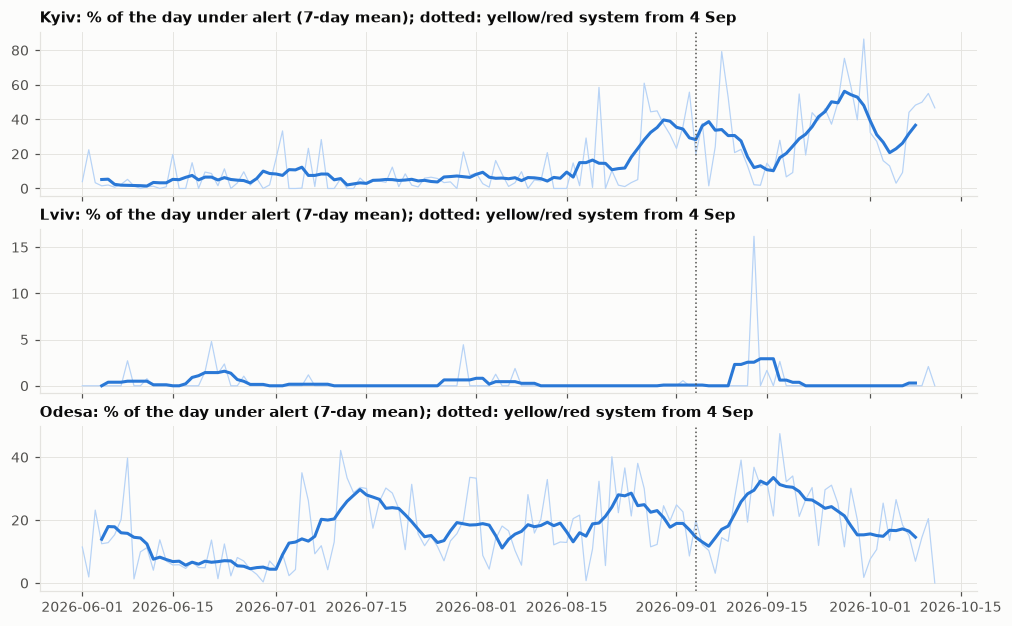

In [7]:
ct.plot_regime(panel['cov_0'].unstack('region'))

Kyiv's share of time under alert **already rose from mid-August, before the switch**, and stayed high (with a dip in mid-September);
Odesa shows **no clear break at 4 Sep**; Lviv stays rare. So the test period differs from the training period both by the new alert
system and by the escalation that began in summer — with five weeks of data the two effects cannot be separated.

## 4. Backtest — same models, validation folds (Feb–Jun) and test folds (5 Sep – 10 Oct, new system)

In [8]:
preds = ct.run_backtest(rerun=False)
board = backtest.leaderboard(preds)
board[board.h == 3].pivot_table(index="model", columns="set", values=["brier", "brier_skill", "roc_auc_mean_per_oblast"]) \
    .sort_values(("brier", "test")).round(4)

brier            brier_skill            roc_auc_mean_per_oblast           
set                 test validation        test validation                    test validation
model                                                                                        
XGBoost           0.1133     0.1221      0.5218     0.1973                  0.7503     0.6939
LightGBM          0.1138     0.1249      0.5196     0.1787                  0.7444     0.6870
logistic AR       0.1157     0.1222      0.5116     0.1962                  0.7524     0.6850
ETS(A,N,A)        0.1296     0.1402      0.4529     0.0780                  0.7440     0.6400
ETS(A,A,A)        0.1296     0.1402      0.4529     0.0780                  0.7440     0.6400
ETS(A,Ad,A)       0.1296     0.1402      0.4529     0.0780                  0.7440     0.6400
ETS(A,N,N)        0.1298     0.1394      0.4518     0.0832                  0.7337     0.6214
AutoETS           0.1298     0.1394      0.4518     0.0832                  0.7337     0.6214
hour-of-day rate  0.2369     0.1521      0.0000     0.0000                  0.5120     0.5113
persistence       0.3313     0.1684     -0.3986    -0.1070                  0.6528     0.6250

In [9]:
p = preds[preds.h == 3].reset_index()
p.groupby(["set", "region"]).agg(actual=("y", "mean"), XGBoost=("XGBoost", "mean"), logistic_AR=("logistic AR", "mean")).round(3)

actual  XGBoost  logistic_AR
set        region                              
test       Kyiv     0.771    0.723        0.677
           Lviv     0.027    0.043        0.036
           Odesa    0.743    0.696        0.706
validation Kyiv     0.204    0.203        0.196
           Lviv     0.054    0.067        0.055
           Odesa    0.418    0.401        0.397

* **Base rates jump** between the validation folds (Feb–Jun) and the test period: the share of hours followed by an alert within 3 h goes
  from 0.20 to 0.77 in Kyiv and from 0.42 to 0.74 in Odesa (summer escalation plus the new system). The hour-of-day baseline, learned under the old system, breaks down — so **Brier skill against it is inflated
  in the test period** and should not be read as a headline.
* **The feature-based models stay calibrated** (Kyiv: 0.72 predicted vs 0.77 actual): they rely on the current state and recent history,
  which adapt immediately to the new regime.

In [10]:
main = ["persistence", "hour-of-day rate", "AutoETS", "logistic AR", "LightGBM", "XGBoost"]
quiet = pd.concat([evaluation.onset_table(preds, panel, h).assign(h=h) for h in config.HORIZONS])
quiet = quiet[quiet.state == "quiet now"]
quiet[quiet.model.isin(main)].pivot_table(index="model", columns=["set", "h"], values="roc_auc_mean_per_oblast").loc[main].round(3)

set                test               validation              
h                     1      3      6          1      3      6
model                                                         
persistence       0.500  0.500  0.500      0.500  0.500  0.500
hour-of-day rate  0.573  0.541  0.528      0.476  0.493  0.494
AutoETS           0.634  0.662  0.688      0.559  0.511  0.472
logistic AR       0.644  0.649  0.655      0.601  0.581  0.565
LightGBM          0.616  0.640  0.618      0.565  0.582  0.555
XGBoost           0.636  0.648  0.651      0.564  0.592  0.570

**Quiet hours (will a new alert start?)** — mean per-city ROC AUC: **0.56–0.60 on validation and 0.62–0.69 on test** for the
feature-based and ETS models, clearly above the baselines but weaker than the main track (0.72–0.76): with only three cities, the "regional state" features carry
much less information than the state of all 24 oblasts. On the test set AutoETS is competitive on quiet hours at 3–6 h — its level adapts
to the new regime by construction.

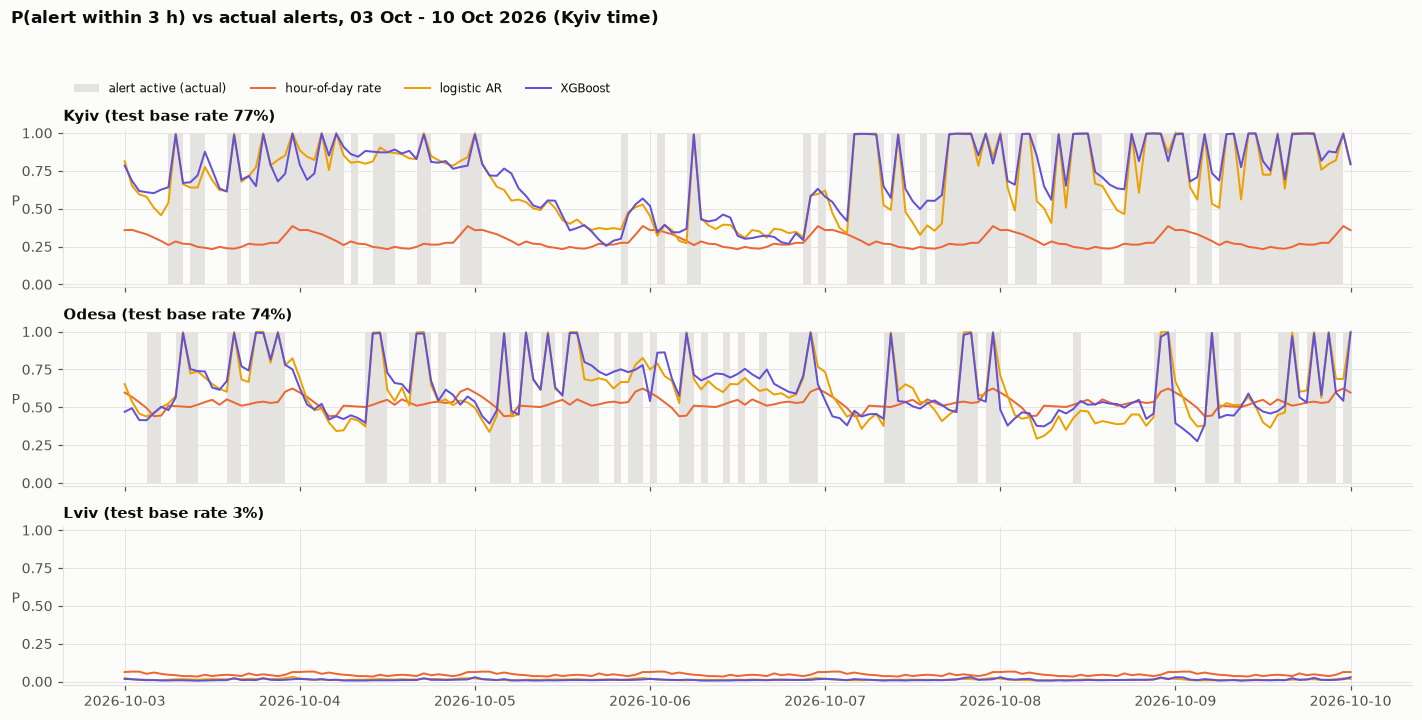

In [11]:
coverage = panel["cov_0"].unstack("region")
evaluation.plot_predictions(preds, coverage, ["Kyiv", "Odesa", "Lviv"], start="2026-10-03", days=7, h=3, name="c02_predictions")

## 5. Latest forecast

In [12]:
fc = ct.latest_forecast(panel)
print(f"forecast made at {fc.attrs['forecast_time'].tz_convert(config.LOCAL_TZ):%Y-%m-%d %H:%M} Kyiv time, data up to that moment only")
fc.round(3)

forecast made at 2026-10-11 01:00 Kyiv time, data up to that moment only


,alert_now,p_1h,p_3h,p_6h
region,,,,
Kyiv,1,0.986,0.991,0.998
Odesa,0,0.174,0.464,0.714
Lviv,0,0.035,0.063,0.073


## 6. Conclusions

* Official city channels for **Kyiv, Lviv and Odesa** reproduce the official alert data almost exactly (recall ≥ 0.98) and continue past
  the end of the official feed — they make an up-to-date forecast possible.
* They also revealed that the **official feed was incomplete in its last ~2 weeks**.
* In the test period (new yellow/red system, after a summer escalation) alerts in Kyiv and Odesa are far more frequent than in
  Feb–Jun; models trained mostly on the old system stay calibrated
  because they follow the current state, but early warning of new alerts is modest (per-city AUC ≈ 0.56–0.69) — the three-city setup
  lacks the regional view of the main track.
* With more data from the new system, the model should be re-trained on it alone; the alert level (yellow / red) could then become a feature.